# Clustering avec DINO + HDBSCAN + UMAP

Léa Maronet - 2026

In [1]:
import os
import numpy as np
import pandas as pd
import glob
import torch
from PIL import Image
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import umap
from io import BytesIO
import base64
import warnings
import hdbscan
from torchvision import transforms
from sklearn.decomposition import PCA

In [2]:
dossier_masques = "../data/masques"
corpusMasques = pd.read_csv("../outputs/corpusMasques.csv", usecols=["Nom_image", "Nom_masque", "Motif", "Site"])
corpusMasques["Nom_image"] = corpusMasques["Nom_image"].str.replace(r"\.[^.]*$", "", regex=True)
corpusMasques

,Nom_masque,Motif,Nom_image,Site
0,ASOK_AND003_lion_13.png,lion,ASOK_AND003,Dupāḍu
1,ASOK_NAG002b_lotus_69.png,lotus,ASOK_NAG002b,Nāgārjunakoṇḍa
2,ASOK_NAG002b_lion_72.png,lion,ASOK_NAG002b,Nāgārjunakoṇḍa
3,ASOK_AND002_lotus_109.png,lotus,ASOK_AND002,Dupāḍu
4,ASOK_AND002_lotus_110.png,lotus,ASOK_AND002,Dupāḍu
...,...,...,...,...
539,ASOK_AMA052_lotus_14203.png,lotus,ASOK_AMA052,Amarāvatī
540,ASOK_AMA053_lotus_14208.png,lotus,ASOK_AMA053,Amarāvatī
541,ASOK_AMA072_lion_14211.png,lion,ASOK_AMA072,Amarāvatī
542,ASOK_AMA072_lion_14212.png,lion,ASOK_AMA072,Amarāvatī


## Fonctions de clustering

In [3]:
#Chargement des images
def chargement_images_par_motif(dossier_masques, corpusMasques, motif):
    masques_motif = set(corpusMasques.loc[corpusMasques["Motif"] == motif, "Nom_masque"])
    images = []
    for filename in sorted(os.listdir(dossier_masques)):
        if filename in masques_motif:
            path = os.path.join(dossier_masques, filename)
            image = Image.open(path).convert("RGB")
            images.append((filename, image))
    return images
     
#Chargement de DINOv2
device = "cuda" if torch.cuda.is_available() else "cpu"
modele = torch.hub.load('facebookresearch/dino:main', 'dino_vitb16') #Ou 'dino_vits16', 'dino_vits8', 'dino_vitb8'
modele = modele.to(device)
modele.eval()
transform_dino = transforms.Compose([
    transforms.Resize(256, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

#Extraction des features DINO
def extraction_dino_features(image):
    img_tensor = transform_dino(image).unsqueeze(0).to(device)
    with torch.no_grad():
        features = modele(img_tensor)
    return features.cpu().numpy().flatten()

#Clustering avec HDBSCAN
def cluster_hdbscan(features, taille_min_cluster, min_voisins):
    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=taille_min_cluster,
        min_samples=min_voisins,
        metric='euclidean',
        cluster_selection_method='eom'
    )
    labels = clusterer.fit_predict(features)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    print(f"[INFO] Nombre de clusters détectés : {n_clusters}")
    print(f"[INFO] Nombre de cas limites (outliers) : {n_noise} ({n_noise/len(labels)*100:.1f}%)")
    return labels, clusterer

Using cache found in /data/home/lmaronet/.cache/torch/hub/facebookresearch_dino_main


In [4]:
def visualisation_clusters(images, etiquettes_num, motif, afficher_dans_notebook, afficher_noms_images=False):
    """
    Fonction pour visualiser et enregistrer les clusters d'images avec options d'affichage.
    Tous les groupes (clusters principaux, sous-clusters, outliers) sont réunis dans une seule image.
    Paramètres : 
    - images : liste de tuples (nom de fichier, image)
    - etiquettes_num : labels de clusters
    - motif : nom du motif
    - afficher_noms_images : affiche ou non le nom du fichier sous chaque image
    - afficher_dans_notebook : affiche ou non les figures dans le notebook 
    """

    max_per_cluster = 1000 #Nombre maximum d'images par cluster
    images_par_ligne = 20 #Nombre d'images par ligne
    taille_vignette_pouces = 1.2
    hauteur_ligne_titre = 0.7
    fontsize_titre_base = 14
    fontsize_noms = 4

    #Détection sous-clusters / outliers
    est_sous_clustering = isinstance(etiquettes_num[0], str) if len(etiquettes_num) > 0 else False

    if est_sous_clustering:
        # Ordre d'affichage : clusters MAIN_ → sous-clusters SUB_ → outliers
        clusters_main = sorted(
            [x for x in set(etiquettes_num) if isinstance(x, str) and x.startswith("MAIN_")],
            key=lambda x: int(x.split("_")[1])
        )
        clusters_sub = sorted(
            [x for x in set(etiquettes_num) if isinstance(x, str) and x.startswith("SUB_")],
            key=lambda x: int(x.split("_")[1])
        )
        clusters_uniques = clusters_main + clusters_sub
        outlier_label = "OUTLIER"
    else:
        clusters_uniques = sorted([x for x in set(etiquettes_num) if x != -1])
        outlier_label = -1

    outlier_images = [
        (filename, img)
        for (filename, img), label in zip(images, etiquettes_num)
        if label == outlier_label
    ]
    n_outliers = len(outlier_images)

    #Calcul du nombre total de lignes (clusters + outliers)
    def compter_lignes(cluster_id):
        cluster_imgs = [
            (fn, img) for (fn, img), label in zip(images, etiquettes_num)
            if label == cluster_id
        ][:max_per_cluster]
        n = len(cluster_imgs)
        return 1 + int(np.ceil(n / images_par_ligne))

    lignes_totales = sum(compter_lignes(cid) for cid in clusters_uniques)
    if n_outliers > 0:
        lignes_totales += 1 + int(np.ceil(n_outliers / images_par_ligne))

    largeur_fig = images_par_ligne * taille_vignette_pouces
    hauteur_fig = (lignes_totales * taille_vignette_pouces
                   + (len(clusters_uniques) + (1 if n_outliers > 0 else 0)) * hauteur_ligne_titre)

    fig = plt.figure(figsize=(largeur_fig, hauteur_fig))
    ligne_actuelle = 0
    fontsize_titre = fontsize_titre_base + 0.002 * largeur_fig * 72

    #Affichage de chaque cluster
    for cluster_id in clusters_uniques:
        cluster_images = [
            (fn, img) for (fn, img), label in zip(images, etiquettes_num)
            if label == cluster_id
        ][:max_per_cluster]
        n_images = len(cluster_images)
        n_lignes_cluster = int(np.ceil(n_images / images_par_ligne))

        if est_sous_clustering:
            if str(cluster_id).startswith("MAIN_"):
                titre = f"Cluster {cluster_id.split('_')[1]} – {n_images} images"
                couleur = 'lightblue'
            else:
                titre = f"Sous-cluster {cluster_id.split('_')[1]} – {n_images} images"
                couleur = 'lightyellow'
        else:
            titre = f"Cluster {cluster_id} – {n_images} images"
            couleur = 'lightblue'

        ax_titre = plt.subplot2grid(
            (lignes_totales, images_par_ligne),
            (ligne_actuelle, 0), colspan=images_par_ligne
        )
        ax_titre.text(
            0.5, 0.5, titre,
            ha='center', va='center',
            fontsize=fontsize_titre, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor=couleur, alpha=0.4)
        )
        ax_titre.axis('off')
        ligne_actuelle += 1

        for i, (filename, img) in enumerate(cluster_images):
            ligne_dans_cluster = i // images_par_ligne
            col = i % images_par_ligne
            ax = plt.subplot2grid(
                (lignes_totales, images_par_ligne),
                (ligne_actuelle + ligne_dans_cluster, col)
            )
            ax.imshow(img)
            ax.axis('off')
            if afficher_noms_images:
                ax.set_title(filename, fontsize=fontsize_noms, pad=1)

        ligne_actuelle += n_lignes_cluster

    #Affichage des outliers
    if n_outliers > 0:
        n_lignes_outliers = int(np.ceil(n_outliers / images_par_ligne))

        ax_titre_outliers = plt.subplot2grid(
            (lignes_totales, images_par_ligne),
            (ligne_actuelle, 0), colspan=images_par_ligne
        )
        ax_titre_outliers.text(
            0.5, 0.5, f"Cas limites – {n_outliers} images",
            ha='center', va='center',
            fontsize=fontsize_titre, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='coral', alpha=0.4)
        )
        ax_titre_outliers.axis('off')
        ligne_actuelle += 1

        for i, (filename, img) in enumerate(outlier_images):
            ligne = i // images_par_ligne
            col = i % images_par_ligne
            ax = plt.subplot2grid(
                (lignes_totales, images_par_ligne),
                (ligne_actuelle + ligne, col)
            )
            ax.imshow(img)
            ax.axis('off')
            if afficher_noms_images:
                ax.set_title(filename, fontsize=fontsize_noms, pad=1)

    plt.subplots_adjust(left=0.01, right=0.99, top=0.98, bottom=0.02, hspace=0.2, wspace=0.02)
    chemin = f"../outputs/clustering/clusters_{motif}.png"
    plt.savefig(chemin, dpi=200)

    if afficher_dans_notebook:
        plt.show()
    plt.close()

In [5]:
#Projection avec l'ensemble des clusters (principaux + sous-clusters + outliers)
def miniature_image(image, size=(64, 64)):
    image_thumb = image.copy()
    image_thumb.thumbnail(size)
    buffered = BytesIO()
    image_thumb.save(buffered, format="PNG")
    image_b64 = base64.b64encode(buffered.getvalue()).decode()
    return f"data:image/png;base64,{image_b64}"

def projection_et_graphique(motif, afficher_images=True, afficher_dans_notebook=False):
    """
    Projection UMAP pour un motif complet.
    Paramètres :
    - motif : nom du motif
    - afficher_images : superposer ou non les miniatures sur la projection (peut être lourd si beaucoup d'images)
    - afficher_dans_notebook : afficher ou non la figure dans le notebook
    """
    
    #Chargement du CSV
    chemin_csv = f"../outputs/clustering/clusters_DINO_HDBSCAN_{motif}.csv"
    df_motif = pd.read_csv(chemin_csv)
    df_motif = df_motif.dropna(subset=["Cluster"])
    df_motif = df_motif.drop_duplicates(subset="Nom_masque")

    #Chargement des images
    noms_masques = set(df_motif["Nom_masque"])
    images_dict = {}
    for filename in sorted(os.listdir(dossier_masques)):
        if filename in noms_masques:
            path = os.path.join(dossier_masques, filename)
            image = Image.open(path).convert("RGB")
            images_dict[filename] = image
    images = [(nom, images_dict[nom]) for nom in df_motif["Nom_masque"] if nom in images_dict]

    #Extraction des features DINO  
    features = np.array([extraction_dino_features(image) for _, image in images])
    features = features / np.linalg.norm(features, axis=1, keepdims=True)
    pca = PCA(n_components=min(50, len(images) - 1), random_state=42)
    features_reduced = pca.fit_transform(features)
    reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    proj = reducer.fit_transform(features_reduced)

    #Étiquettes finales
    filenames = [name for name, _ in images]
    etiquettes = [df_motif.loc[df_motif["Nom_masque"] == fn, "Cluster"].values[0] for fn in filenames]
    sites = [df_motif.loc[df_motif["Nom_masque"] == fn, "Site"].values[0] for fn in filenames]
    miniatures = [miniature_image(image) for _, image in images]
    hover_text = [f"<b>{fn}</b><br><img src='{thumb}' width='64'>" for fn, thumb in zip(filenames, miniatures)]

    #Typologie des points
    types_points = []
    symboles = []
    cluster_labels = []

    for label in etiquettes:
        label = str(label)
        if label == "OUTLIER":
            types_points.append("Outliers")
            symboles.append("x")
            cluster_labels.append("Cas limites")
        elif label.startswith("SUB_"):
            num = label.split("_")[1]
            types_points.append("Sous-clusters")
            symboles.append("square")
            cluster_labels.append(f"Sous-cluster {num}")
        elif label.startswith("MAIN_"):
            num = label.split("_")[1]
            types_points.append("Clusters")
            symboles.append("circle")
            cluster_labels.append(f"Cluster principal {num}")
        else:
            types_points.append("Autres")
            symboles.append("circle")
            cluster_labels.append(label)

    #Dataframe projection
    df_proj = pd.DataFrame({
        "x": proj[:, 0],
        "y": proj[:, 1],
        "hover_text": hover_text,
        "fn": filenames,
        "Site": sites,
        "Cluster": cluster_labels,
        "Type": types_points,
        "Symbole": symboles,
        "cluster_raw": etiquettes,
        "miniature": miniatures
    })

    #Figure Plotly
    fig = go.Figure()
    palette = (px.colors.qualitative.Plotly + px.colors.qualitative.Set1 + px.colors.qualitative.Set2)
    clusters_uniques = df_proj["Cluster"].unique()
    color_map = {}
    color_idx = 0

    for cluster in sorted([c for c in clusters_uniques if c.startswith("Cluster principal")]):
        color_map[cluster] = palette[color_idx % len(palette)]
        color_idx += 1

    for cluster in sorted([c for c in clusters_uniques if c.startswith("Sous-cluster")]):
        color_map[cluster] = palette[color_idx % len(palette)]
        color_idx += 1

    color_map["Cas limites"] = "gray"

    for cluster in clusters_uniques:
        if cluster not in color_map:
            color_map[cluster] = palette[color_idx % len(palette)]
            color_idx += 1

    def tri_clusters(nom):
        if nom == "Cas limites":
            return (3, 0)
        elif nom.startswith("Cluster principal"):
            return (1, int(nom.split(" ")[-1]))
        elif nom.startswith("Sous-cluster"):
            return (2, int(nom.split(" ")[-1]))
        else:
            return (4, 0)

    for cluster in sorted(clusters_uniques, key=tri_clusters):
        df_cluster = df_proj[df_proj["Cluster"] == cluster]
        fig.add_trace(go.Scatter(
            x=df_cluster["x"],
            y=df_cluster["y"],
            mode="markers",
            name=cluster,
            marker=dict(
                size=8 if df_cluster["Symbole"].iloc[0] != "x" else 10,
                symbol=df_cluster["Symbole"].iloc[0],
                color=color_map[cluster],
                line=dict(width=0.5, color="white")
            ),
            text=df_cluster["fn"],
            hovertext=df_cluster["fn"],
            hovertemplate="%{hovertext}<extra></extra>",
            showlegend=True
        ))

    fig.update_layout(
        title=f"Projection UMAP – {motif}",
        width=1100,
        height=600,
        legend=dict(
            title="Clusters",
            y=1,
            x=1.02,
            bgcolor="white",
            bordercolor="lightgray",
            borderwidth=1
        )
    )

    if afficher_images:
        for _, row in df_proj.iterrows():
            fig.add_layout_image(dict(
                source=row["miniature"], 
                x=row["x"],
                y=row["y"],
                xref="x",
                yref="y",
                sizex=0.1,
                sizey=0.1,
                layer="above"
            ))

    #Sauvegarde
    chemin_html = f"../outputs/clustering/umap_{motif}.html"
    fig.write_html(chemin_html, include_plotlyjs="cdn")
    print(f"[INFO] Projection UMAP sauvegardée : {chemin_html}")
    if afficher_dans_notebook:
        fig.show()
    return fig

In [6]:
#Fonction finale
def clustering_dino_hdbscan(motif, taille_min_cluster=10, min_voisins=1, afficher_images=True, afficher_dans_notebook=False):
    """
    Fonction pour réaliser du clustering sur les masques situés dans ../data/masques.
    Paramètres :
        - motif = nom du motif, en français
        - taille_min_cluster = taille minimale d'un cluster
        - min_voisins = nombre minimum de voisins pour qu'un point soit considéré comme un centre
        - afficher_images = afficher les images dans la projection UMAP, chargement plus lourd 
        - afficher_dans_notebook : affiche ou non les figures dans le notebook 
    """
    
    motif = motif

    #Chargement des images
    images = chargement_images_par_motif(dossier_masques, corpusMasques, motif)
    print(f"\n[INFO] {len(images)} images chargées pour le motif '{motif}'")
    noms_masques = [nom_fichier for nom_fichier, _ in images]
    df_match = corpusMasques[(corpusMasques["Nom_masque"].isin(noms_masques)) & (corpusMasques["Motif"] == motif)][["Nom_masque", "Site"]]
    map_masque_site = dict(zip(df_match["Nom_masque"], df_match["Site"]))
    sites_filtres = [map_masque_site.get(nom, None) for nom in noms_masques]

    #Extraction des features DINO
    features = np.array([extraction_dino_features(image) for _, image in images])
    features = features / np.linalg.norm(features, axis=1, keepdims=True)
    pca = PCA(n_components=min(50, len(images) - 1), random_state=42)
    features_reduced = pca.fit_transform(features)
    etiquettes, clusterer = cluster_hdbscan(features_reduced, taille_min_cluster, min_voisins)

    #Visualisation des clusters (fichier unique par motif)
    visualisation_clusters(images, etiquettes, motif, afficher_dans_notebook=afficher_dans_notebook, afficher_noms_images=True)
    warnings.filterwarnings('ignore')

    #Construction du CSV par motif
    df_corpus = corpusMasques[corpusMasques["Motif"] == motif][["Nom_image", "Nom_masque", "Motif", "Site"]].copy()
    df_clusters = pd.DataFrame({"Nom_masque": noms_masques, "Cluster_HDBSCAN": etiquettes})
    df_motif = df_corpus.merge(df_clusters, on="Nom_masque", how="left")
    
    def normaliser_cluster(label):
        if pd.isna(label):
            return ""
        label = int(label)
        if label == -1:
            return "OUTLIER"
        return f"MAIN_{label}"
    
    df_motif["Cluster"] = df_motif["Cluster_HDBSCAN"].apply(normaliser_cluster)
    chemin_sortie = f"../outputs/clustering/clusters_DINO_HDBSCAN_{motif}.csv"
    df_motif.to_csv(chemin_sortie, index=False)

In [7]:
#Fonction finale cas limites et sous-clusters
def clustering_outliers_dino_hdbscan(motif, taille_min_cluster=2, min_voisins=1, afficher_images=True, afficher_dans_notebook=False):
    """
    Re-clustering des cas limites (outliers) d'un motif déjà clusterisé.
    
    Paramètres :
    - motif = nom du motif, en français
    - taille_min_cluster = taille minimale d'un cluster pour les outliers (recommandé: 3)
    - min_voisins = nombre minimum de voisins
    - afficher_images = afficher les images dans la projection UMAP
    - afficher_dans_notebook : affiche ou non les figures dans le notebook 
    """

    #Chargement du CSV avec les outliers
    chemin_csv = f"../outputs/clustering/clusters_DINO_HDBSCAN_{motif}.csv"
    df_motif = pd.read_csv(chemin_csv)
    mask_outliers = df_motif["Cluster"] == "OUTLIER"
    df_outliers = df_motif[mask_outliers].copy()
    n_outliers = len(df_outliers)
    print(f"[INFO] {n_outliers} cas limites détectés pour le motif '{motif}'")

    #Chargement des images des outliers
    noms_outliers = set(df_outliers["Nom_masque"])
    images_outliers = []
    for filename in sorted(os.listdir(dossier_masques)):
        if filename in noms_outliers:
            path = os.path.join(dossier_masques, filename)
            image = Image.open(path).convert("RGB")
            images_outliers.append((filename, image))

    #Extraction des features DINO
    features = np.array([extraction_dino_features(image) for _, image in images_outliers])
    features = features / np.linalg.norm(features, axis=1, keepdims=True)
    pca = PCA(n_components=min(50, len(images_outliers) - 1), random_state=42)
    features_reduced = pca.fit_transform(features)
    etiquettes_sub, _ = cluster_hdbscan(features_reduced, taille_min_cluster, min_voisins)

    #Renommage des sous-clusters
    etiquettes_renommees = []
    for label in etiquettes_sub:
        if label == -1:
            etiquettes_renommees.append("OUTLIER")
        else:
            etiquettes_renommees.append(f"SUB_{label}")

    #Mise à jour du CSV
    dict_nouveaux_labels = dict(zip([nom for nom, _ in images_outliers], etiquettes_renommees))
    for nom_masque, nouveau_label in dict_nouveaux_labels.items():
        mask = df_motif["Nom_masque"] == nom_masque
        df_motif.loc[mask, "Cluster"] = nouveau_label
    df_motif.to_csv(chemin_csv, index=False)
    print(f"[INFO] CSV motif mis à jour : {chemin_csv}")
    chemin = f"../outputs/clustering/clusters_{motif}.png"
    print(f"[INFO] Clusters sauvegardés : {chemin}")

    # Rechargement de TOUTES les images du motif pour la visualisation unifiée
    noms_tous = set(df_motif["Nom_masque"])
    images_toutes = []
    for filename in sorted(os.listdir(dossier_masques)):
        if filename in noms_tous:
            path = os.path.join(dossier_masques, filename)
            image = Image.open(path).convert("RGB")
            images_toutes.append((filename, image))

    etiquettes_toutes = [
        df_motif.loc[df_motif["Nom_masque"] == fn, "Cluster"].values[0]
        for fn, _ in images_toutes
    ]

    #Visualisation unifiée (clusters MAIN_ + sous-clusters SUB_ + outliers restants)
    visualisation_clusters(
        images_toutes, etiquettes_toutes, motif,
        afficher_dans_notebook=afficher_dans_notebook,
        afficher_noms_images=True
    )

    #Projection UMAP
    projection_et_graphique(motif, afficher_images=afficher_images, afficher_dans_notebook=afficher_dans_notebook)

## Taureau

In [8]:
clustering_dino_hdbscan("taureau", taille_min_cluster=2)


[INFO] 15 images chargées pour le motif 'taureau'
[INFO] Nombre de clusters détectés : 5
[INFO] Nombre de cas limites (outliers) : 2 (13.3%)


[INFO] 2 cas limites détectés pour le motif 'taureau'
[INFO] Nombre de clusters détectés : 0
[INFO] Nombre de cas limites (outliers) : 2 (100.0%)
[INFO] CSV motif mis à jour : ../outputs/clustering/clusters_DINO_HDBSCAN_taureau.csv
[INFO] Clusters sauvegardés : ../outputs/clustering/clusters_taureau.png


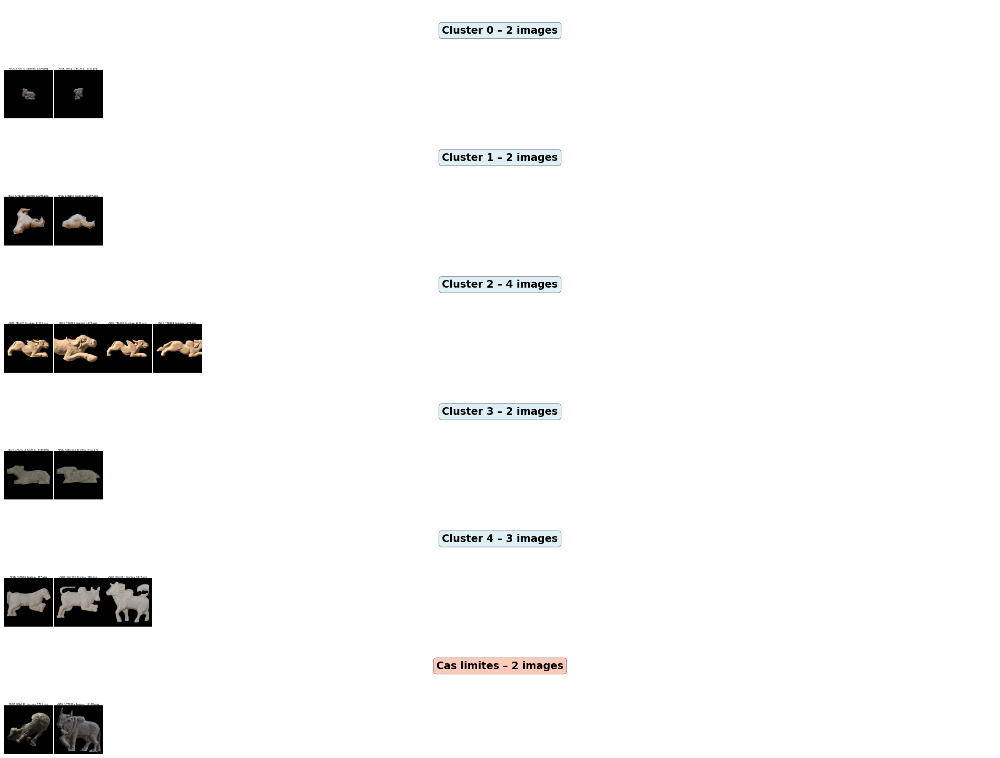

[INFO] Projection UMAP sauvegardée : ../outputs/clustering/umap_taureau.html


In [9]:
clustering_outliers_dino_hdbscan("taureau", taille_min_cluster=2, afficher_dans_notebook=True)

## Lion

In [10]:
clustering_dino_hdbscan("lion", taille_min_cluster=2)


[INFO] 74 images chargées pour le motif 'lion'
[INFO] Nombre de clusters détectés : 21
[INFO] Nombre de cas limites (outliers) : 8 (10.8%)


[INFO] 8 cas limites détectés pour le motif 'lion'
[INFO] Nombre de clusters détectés : 2
[INFO] Nombre de cas limites (outliers) : 3 (37.5%)
[INFO] CSV motif mis à jour : ../outputs/clustering/clusters_DINO_HDBSCAN_lion.csv
[INFO] Clusters sauvegardés : ../outputs/clustering/clusters_lion.png


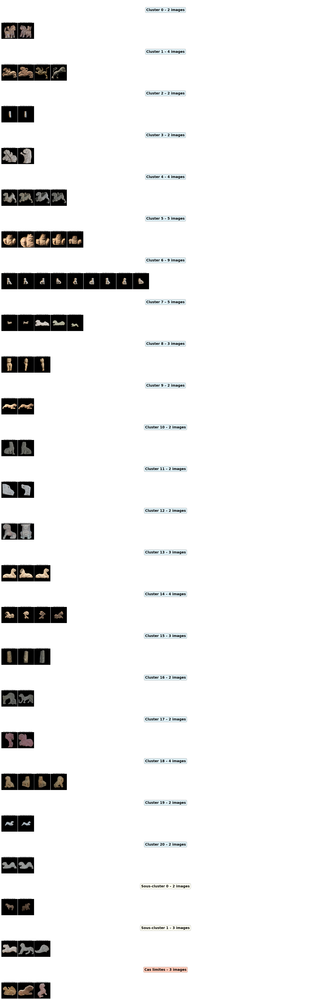

[INFO] Projection UMAP sauvegardée : ../outputs/clustering/umap_lion.html


In [11]:
clustering_outliers_dino_hdbscan("lion", taille_min_cluster=2, afficher_dans_notebook=True)

## Oie

In [12]:
clustering_dino_hdbscan("oie", taille_min_cluster=2)


[INFO] 20 images chargées pour le motif 'oie'
[INFO] Nombre de clusters détectés : 7
[INFO] Nombre de cas limites (outliers) : 2 (10.0%)


In [13]:
clustering_outliers_dino_hdbscan("oie", taille_min_cluster=2)

[INFO] 2 cas limites détectés pour le motif 'oie'
[INFO] Nombre de clusters détectés : 0
[INFO] Nombre de cas limites (outliers) : 2 (100.0%)
[INFO] CSV motif mis à jour : ../outputs/clustering/clusters_DINO_HDBSCAN_oie.csv
[INFO] Clusters sauvegardés : ../outputs/clustering/clusters_oie.png
[INFO] Projection UMAP sauvegardée : ../outputs/clustering/umap_oie.html


## Éléphant

In [14]:
clustering_dino_hdbscan("éléphant", taille_min_cluster=2)


[INFO] 48 images chargées pour le motif 'éléphant'
[INFO] Nombre de clusters détectés : 13
[INFO] Nombre de cas limites (outliers) : 13 (27.1%)


In [15]:
clustering_outliers_dino_hdbscan("éléphant", taille_min_cluster=2)

[INFO] 13 cas limites détectés pour le motif 'éléphant'
[INFO] Nombre de clusters détectés : 0
[INFO] Nombre de cas limites (outliers) : 13 (100.0%)
[INFO] CSV motif mis à jour : ../outputs/clustering/clusters_DINO_HDBSCAN_éléphant.csv
[INFO] Clusters sauvegardés : ../outputs/clustering/clusters_éléphant.png
[INFO] Projection UMAP sauvegardée : ../outputs/clustering/umap_éléphant.html


## Cheval

In [16]:
clustering_dino_hdbscan("cheval", taille_min_cluster=2)


[INFO] 18 images chargées pour le motif 'cheval'
[INFO] Nombre de clusters détectés : 5
[INFO] Nombre de cas limites (outliers) : 2 (11.1%)


In [17]:
clustering_outliers_dino_hdbscan("cheval", taille_min_cluster=2)

[INFO] 2 cas limites détectés pour le motif 'cheval'
[INFO] Nombre de clusters détectés : 0
[INFO] Nombre de cas limites (outliers) : 2 (100.0%)
[INFO] CSV motif mis à jour : ../outputs/clustering/clusters_DINO_HDBSCAN_cheval.csv
[INFO] Clusters sauvegardés : ../outputs/clustering/clusters_cheval.png
[INFO] Projection UMAP sauvegardée : ../outputs/clustering/umap_cheval.html


## Lotus

In [18]:
clustering_dino_hdbscan("lotus", taille_min_cluster=5)


[INFO] 369 images chargées pour le motif 'lotus'
[INFO] Nombre de clusters détectés : 24
[INFO] Nombre de cas limites (outliers) : 93 (25.2%)


[INFO] 93 cas limites détectés pour le motif 'lotus'
[INFO] Nombre de clusters détectés : 16
[INFO] Nombre de cas limites (outliers) : 30 (32.3%)
[INFO] CSV motif mis à jour : ../outputs/clustering/clusters_DINO_HDBSCAN_lotus.csv
[INFO] Clusters sauvegardés : ../outputs/clustering/clusters_lotus.png





[INFO] Projection UMAP sauvegardée : ../outputs/clustering/umap_lotus.html


In [19]:
clustering_outliers_dino_hdbscan("lotus", taille_min_cluster=3, afficher_dans_notebook=True)

## Merge et export du dataframe

In [26]:
corpusMasques = pd.read_csv("../outputs/corpusMasques.csv")
dfClustersMotifs = [pd.read_csv(csv) for csv in glob.glob("../outputs/clustering/clusters_DINO_HDBSCAN_*.csv")]
dfClusters = pd.concat(dfClustersMotifs, ignore_index=True).drop(columns=["Site", "Cluster_HDBSCAN"])
corpusMasquesClusters = dfClusters.merge(corpusMasques.drop(columns=["Motif", "Nom_image"]), left_on="Nom_masque", right_on="Nom_masque", how="left")
corpusMasquesClusters.to_csv("../outputs/corpusMasquesClusters.csv", index=False)
corpusMasquesClusters

,Nom_image,Nom_masque,Motif,Cluster,Polygone,Confiance,Titre,État,Région,Site,Description,Date,Support,Affiliation religieuse,Lieu de conservation,Auteur
0,ASOK_AND003,ASOK_AND003_lion_13.png,lion,MAIN_1,"[[243, 2456], [335, 2548], [318, 2632], [402, ...",0.98,ASOK_AND003,Andhra Pradesh,Āndhradeśa,Dupāḍu,Animaux ailés,1 A.D.,Stūpa ; frise,bouddhisme,Amaravati Heritage Centre and Museum,Maronet Léa
1,ASOK_NAG002b,ASOK_NAG002b_lion_72.png,lion,MAIN_7,"[[316, 802], [326, 806], [325, 815], [338, 841...",0.97,ASOK_NAG002b,Andhra Pradesh,Āndhradeśa,Nāgārjunakoṇḍa,Demi-médaillon lotiforme et lion,3 A.D.,Pilier,bouddhisme,In situ,Maronet Léa
2,ASOK_AMA072,ASOK_AMA072_lion_178.png,lion,MAIN_6,"[[482, 790], [488, 794], [495, 793], [501, 791...",0.97,ASOK_AMA072,Andhra Pradesh,Āndhradeśa,Amarāvatī,Stūpa figuré ; Buddha entourré de dévots et pi...,1 A.D. ; 2 A.D. ; 3 A.D.,Stūpa ; panneau,bouddhisme,The British Museum,Maronet Léa
3,ASOK_AMA072,ASOK_AMA072_lion_181.png,lion,MAIN_6,"[[502, 870], [502, 881], [505, 887], [504, 890...",1.00,ASOK_AMA072,Andhra Pradesh,Āndhradeśa,Amarāvatī,Stūpa figuré ; Buddha entourré de dévots et pi...,1 A.D. ; 2 A.D. ; 3 A.D.,Stūpa ; panneau,bouddhisme,The British Museum,Maronet Léa
4,ASOK_AMA072,ASOK_AMA072_lion_193.png,lion,MAIN_6,"[[230, 840], [231, 852], [238, 884], [238, 894...",0.98,ASOK_AMA072,Andhra Pradesh,Āndhradeśa,Amarāvatī,Stūpa figuré ; Buddha entourré de dévots et pi...,1 A.D. ; 2 A.D. ; 3 A.D.,Stūpa ; panneau,bouddhisme,The British Museum,Maronet Léa
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539,ASOK_AMA005,ASOK_AMA005_lotus_14190.png,lotus,MAIN_15,"[[45, 966], [49, 981], [492, 981], [490, 860],...",0.98,ASOK_AMA005,Andhra Pradesh,Āndhradeśa,Amarāvatī,Pilier de balustrade avec médaillons lotiforme...,1 A.D. ; 2 A.D. ; 3 A.D.,Stūpa ; balustrade ; pilier,bouddhisme,The British Museum,Maronet Léa
540,ASOK_AMA009,ASOK_AMA009_lotus_14196.png,lotus,OUTLIER,"[[19, 990], [62, 982], [95, 955], [160, 1010],...",1.00,ASOK_AMA009,Andhra Pradesh,Āndhradeśa,Amarāvatī,Pilier de balustrade avec médaillons lotiforme...,1 A.D. ; 2 A.D. ; 3 A.D.,Stūpa ; balustrade ; pilier,bouddhisme,The British Museum,Maronet Léa
541,ASOK_AMA052,ASOK_AMA052_lotus_14202.png,lotus,MAIN_15,"[[85, 1049], [97, 1720], [158, 1754], [226, 17...",1.00,ASOK_AMA052,Andhra Pradesh,Āndhradeśa,Amarāvatī,Pilier de balustrade avec médaillon et demi-mé...,1 A.D. ; 2 A.D. ; 3 A.D.,Stūpa ; balustrade ; pilier,bouddhisme,Chennai Government Museum,Maronet Léa
542,ASOK_AMA052,ASOK_AMA052_lotus_14203.png,lotus,MAIN_15,"[[107, 2071], [139, 2233], [156, 2318], [168, ...",0.97,ASOK_AMA052,Andhra Pradesh,Āndhradeśa,Amarāvatī,Pilier de balustrade avec médaillon et demi-mé...,1 A.D. ; 2 A.D. ; 3 A.D.,Stūpa ; balustrade ; pilier,bouddhisme,Chennai Government Museum,Maronet Léa


In [27]:
#Ménage
for file in glob.glob("../outputs/clustering/clusters_DINO_HDBSCAN_*.csv"):
    os.remove(file)